# Follow-up analyses (Addendum A of `docs/analysis-plan.md`)

These checks were proposed **after** the results of notebook 01 were seen, and the addendum was
committed before they were run. Run notebook 01 first: this notebook reads its `results/` files.

- **A1** Independent single-cell check in two trophoblast classes (different donors, different study)
- **A2** Is glycolysis a shared placental stress signal, with hypoxia more PE-linked? (direct group contrasts)
- **A3** Are hypoxia and glycolysis separate signals? (shared vs set-specific genes)

In [1]:
import os, sys, subprocess, warnings, itertools
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path("..")
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
PB_DIR = DATA_DIR / "extension" / "pseudobulk"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
assert (RES_DIR / "robust_hits.csv").exists(), "Run notebook 01 first"

gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(ROOT / "data_external" / "h.all.v2024.1.Hs.symbols.gmt")}
HYP, GLY = set(gmt["HALLMARK_HYPOXIA"]), set(gmt["HALLMARK_GLYCOLYSIS"])
robust = pd.read_csv(RES_DIR / "robust_hits.csv", index_col=0)
print(f"Robust bulk hits from notebook 01: {len(robust)}  (up {int((robust.log2FoldChange > 0).sum())}, down {int((robust.log2FoldChange < 0).sum())})")

Robust bulk hits from notebook 01: 207  (up 148, down 59)


## A1. Independent single-cell check (pseudobulk, early-onset PE 10 donors vs early controls 3 donors)
One column per donor and cell class, so each donor counts once. With 13 donors there are only
C(13,3) = 286 ways to choose the 3 "controls", so we compute **exact** permutation p-values.
The smallest possible p-value is 1/286 = 0.0035. Exploratory.

In [2]:
pb = pd.read_csv(PB_DIR / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(PB_DIR / "track01_pseudobulk_metadata.csv", index_col=0)
CLASSES = ["villous_cytotrophoblast", "syncytiotrophoblast"]
early = pbm[pbm.early_onset_comparison.str.startswith("exploratory")]
print(early[early.cell_class.isin(CLASSES)].pivot_table(index="donor_id", columns="cell_class", values="n_cells"))

def log_cpm(c):
    return np.log2(c / c.sum(axis=0) * 1e6 + 1)

def perm_splits(n, k):
    return [list(s) for s in itertools.combinations(range(n), k)]

a1_rows, a1_scores = [], {}
for cls in CLASSES:
    md = early[early.cell_class == cls].sort_values("pe_status")
    c = pb[md.index]
    c = c.loc[(c >= 10).sum(axis=1) >= 3]
    lc = log_cpm(c)
    is_ctrl = (md.pe_status == "control").values
    n = len(md); splits = perm_splits(n, int(is_ctrl.sum()))

    # (a) direction concordance with robust bulk hits
    genes = robust.index.intersection(lc.index)
    bulk_sign = np.sign(robust.loc[genes, "log2FoldChange"].values)
    def concord(ctrl_idx):
        mask = np.zeros(n, bool); mask[ctrl_idx] = True
        d = lc.loc[genes].values[:, ~mask].mean(1) - lc.loc[genes].values[:, mask].mean(1)
        return np.mean(np.sign(d) == bulk_sign)
    obs = concord(np.where(is_ctrl)[0])
    null = np.array([concord(s) for s in splits])
    p_conc = np.mean(null >= obs)

    # (b) pathway scores within the class (z across the 13 donors)
    z = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
    sc = pd.DataFrame({"hypoxia": z.loc[z.index.intersection(list(HYP))].mean(),
                       "glycolysis": z.loc[z.index.intersection(list(GLY))].mean()})
    sc["pe_status"] = md.pe_status.values; sc["donor_id"] = md.donor_id.values
    a1_scores[cls] = sc
    row = {"cell_class": cls, "n_PE": int((~is_ctrl).sum()), "n_ctrl": int(is_ctrl.sum()),
           "bulk_hits_expressed": len(genes), "concordance": obs,
           "concordance_null_median": np.median(null), "concordance_perm_p": p_conc}
    for s in ["hypoxia", "glycolysis"]:
        v = sc[s].values
        diff = lambda m: v[~m].mean() - v[m].mean()
        obs_d = diff(is_ctrl)
        null_d = []
        for sp in splits:
            m = np.zeros(n, bool); m[sp] = True; null_d.append(diff(m))
        null_d = np.array(null_d)
        loo = [np.delete(v, i)[~np.delete(is_ctrl, i)].mean() - np.delete(v, i)[np.delete(is_ctrl, i)].mean() for i in range(n)]
        row[f"{s}_diff"] = obs_d
        row[f"{s}_perm_p_two_sided"] = np.mean(np.abs(null_d) >= abs(obs_d) - 1e-12)
        row[f"{s}_LOO_min"], row[f"{s}_LOO_max"] = min(loo), max(loo)
    a1_rows.append(row)

a1 = pd.DataFrame(a1_rows).set_index("cell_class")
a1.to_csv(RES_DIR / "A1_pseudobulk.csv")
print(a1.T.round(3))

cell_class       syncytiotrophoblast  villous_cytotrophoblast
donor_id                                                     
PE_early_1                     327.0                   1805.0
PE_early_10                     94.0                    291.0
PE_early_2                      74.0                    433.0
PE_early_3                      47.0                    299.0
PE_early_4                      36.0                    139.0
PE_early_5                     128.0                    512.0
PE_early_6                      69.0                    301.0
PE_early_7                     255.0                   1485.0
PE_early_8                     101.0                   1080.0
PE_early_9                     315.0                    894.0
control_early_1                405.0                   1372.0
control_early_2                 96.0                    372.0
control_early_3                157.0                    984.0


cell_class                   villous_cytotrophoblast  syncytiotrophoblast
n_PE                                          10.000               10.000
n_ctrl                                         3.000                3.000
bulk_hits_expressed                          135.000              107.000
concordance                                    0.681                0.785
concordance_null_median                        0.485                0.514
concordance_perm_p                             0.147                0.091
hypoxia_diff                                   0.272                0.356
hypoxia_perm_p_two_sided                       0.150                0.080
hypoxia_LOO_min                                0.157                0.268
hypoxia_LOO_max                                0.381                0.420
glycolysis_diff                                0.113                0.040
glycolysis_perm_p_two_sided                    0.570                0.822
glycolysis_LOO_min                    

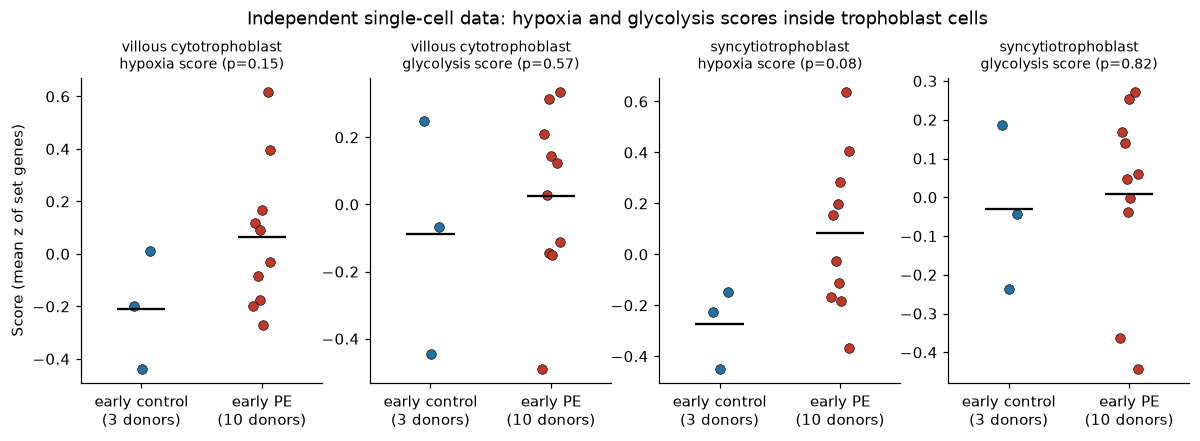

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=False)
for j, cls in enumerate(CLASSES):
    for k, s in enumerate(["hypoxia", "glycolysis"]):
        ax = axes[2 * j + k]; sc = a1_scores[cls]
        for x, (lab, col) in enumerate([("control", "#2471a3"), ("PE", "#c0392b")]):
            v = sc[sc.pe_status == lab][s]
            ax.scatter(np.full(len(v), x) + np.random.default_rng(1).uniform(-0.08, 0.08, len(v)), v, c=col, s=40, edgecolor="k", lw=0.4)
            ax.hlines(v.mean(), x - 0.2, x + 0.2, color="k")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["early control\n(3 donors)", "early PE\n(10 donors)"])
        ax.set_xlim(-0.5, 1.5)
        ax.set_title(f"{cls.replace('_', ' ')}\n{s} score (p={a1.loc[cls, s + '_perm_p_two_sided']:.2f})", fontsize=9)
axes[0].set_ylabel("Score (mean z of set genes)")
fig.suptitle("Independent single-cell data: hypoxia and glycolysis scores inside trophoblast cells", y=1.05)
plt.savefig(FIG_DIR / "fig5_pseudobulk_trophoblast.png", dpi=300, bbox_inches="tight"); plt.show()

Secondary, exploratory: all 26 donors (early and late), `score ~ PE + gestational age`.

In [4]:
sec = []
for cls in CLASSES:
    md = pbm[pbm.cell_class == cls]
    c = pb[md.index]; c = c.loc[(c >= 10).sum(axis=1) >= 3]; lc = log_cpm(c)
    z = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
    d = md[["pe_status", "ga_delivery_weeks", "fetal_sex"]].copy()
    d["PE"] = (d.pe_status == "PE").astype(int)
    d["hypoxia"] = z.loc[z.index.intersection(list(HYP))].mean().values
    d["glycolysis"] = z.loc[z.index.intersection(list(GLY))].mean().values
    for s in ["hypoxia", "glycolysis"]:
        f = smf.ols(f"{s} ~ PE + ga_delivery_weeks", data=d).fit()
        ci = f.conf_int().loc["PE"]
        sec.append({"cell_class": cls, "score": s, "n": len(d), "PE_coef": f.params["PE"], "CI_low": ci[0], "CI_high": ci[1], "p": f.pvalues["PE"]})
sec = pd.DataFrame(sec); sec.to_csv(RES_DIR / "A1_secondary_all_donors.csv", index=False)
print(sec.round(3))

                cell_class       score   n  PE_coef  CI_low  CI_high      p
0  villous_cytotrophoblast     hypoxia  26    0.244   0.042    0.445  0.020
1  villous_cytotrophoblast  glycolysis  26    0.193  -0.018    0.404  0.071
2      syncytiotrophoblast     hypoxia  26    0.296   0.070    0.523  0.013
3      syncytiotrophoblast  glycolysis  26    0.118  -0.089    0.325  0.251


## A2 + A3. Group effect sizes in bulk, for hypoxia, glycolysis, and shared / set-specific genes
25 preterm placentas (term controls excluded). OLS `score ~ group + gestational age + fetal sex`, iPTB as reference.
The key numbers are the **direct** contrasts EOPE − FGR-only and PE (both PE groups) − FGR-only.

In [5]:
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
dds = DeseqDataSet(counts=counts.T.astype(int), metadata=meta[["pe_status"]], design="~pe_status",
                   inference=DefaultInference(n_cpus=4), quiet=True)
dds.fit_size_factors(); dds.vst(use_design=False)
vst = pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)
z = (vst - vst.mean()) / vst.std()

gene_sets = {"hypoxia (all)": HYP, "glycolysis (all)": GLY, "shared genes": HYP & GLY,
             "hypoxia-only genes": HYP - GLY, "glycolysis-only genes": GLY - HYP}
S = pd.DataFrame({k: z[[g for g in v if g in z.columns]].mean(axis=1) for k, v in gene_sets.items()})
for k, v in gene_sets.items():
    print(f"{k:<22} {sum(g in z.columns for g in v):>3} of {len(v)} genes measured")

pre = meta.index[meta.group != "TB"]
d = S.loc[pre].copy()
d.columns = ["hyp_all", "gly_all", "shared", "hyp_only", "gly_only"]
d = d.join(meta[["group", "ga_delivery_weeks", "fetal_sex"]])
d["grp"] = d.group.map({"iPTB": "iPTB", "EOPE": "EOPE", "EOPE+FGR": "EOPEFGR", "FGR": "FGR"})

labels = dict(zip(d.columns[:5], gene_sets.keys()))
rows = []
for s in labels:
    for cov in ["nonrobust", "HC3"]:
        f = smf.ols(f"{s} ~ C(grp, Treatment('iPTB')) + ga_delivery_weeks + C(fetal_sex)", data=d).fit(cov_type=cov)
        names = {g: f"C(grp, Treatment('iPTB'))[T.{g}]" for g in ["EOPE", "EOPEFGR", "FGR"]}
        contrasts = {"EOPE vs iPTB": {names["EOPE"]: 1}, "EOPE+FGR vs iPTB": {names["EOPEFGR"]: 1},
                     "FGR-only vs iPTB": {names["FGR"]: 1},
                     "EOPE vs FGR-only": {names["EOPE"]: 1, names["FGR"]: -1},
                     "PE (both) vs FGR-only": {names["EOPE"]: 0.5, names["EOPEFGR"]: 0.5, names["FGR"]: -1}}
        for cname, w in contrasts.items():
            L = np.zeros(len(f.params));
            for k, v in w.items(): L[list(f.params.index).index(k)] = v
            t = f.t_test(L); ci = t.conf_int()[0]
            rows.append({"score": labels[s], "se": cov, "contrast": cname, "estimate": float(t.effect[0]),
                         "std_err": float(np.ravel(t.sd)[0]), "df_resid": float(f.df_resid),
                         "CI_low": ci[0], "CI_high": ci[1], "p": float(t.pvalue)})
a2 = pd.DataFrame(rows); a2.to_csv(RES_DIR / "A2_A3_group_contrasts.csv", index=False)
print(a2[a2.se == "nonrobust"].pivot_table(index="contrast", columns="score", values="estimate", sort=False).round(2))
print()
print(a2[a2.se == "nonrobust"].pivot_table(index="contrast", columns="score", values="p", sort=False).round(3))
print("\nHC3 p-values for the direct contrasts:")
print(a2[(a2.se == "HC3") & a2.contrast.str.contains("vs FGR")].pivot_table(index="contrast", columns="score", values="p", sort=False).round(3))
r, p = stats.spearmanr(d.hyp_only, d.gly_only)
print(f"\nPer-sample correlation, hypoxia-only vs glycolysis-only scores (25 preterm): rho = {r:.2f}, p = {p:.3g}")

hypoxia (all)          177 of 200 genes measured
glycolysis (all)       177 of 200 genes measured
shared genes            59 of 65 genes measured
hypoxia-only genes     118 of 135 genes measured
glycolysis-only genes  118 of 135 genes measured
score                  hypoxia (all)  glycolysis (all)  shared genes  \
contrast                                                               
EOPE vs iPTB                    0.54              0.30          0.76   
EOPE+FGR vs iPTB                0.35              0.28          0.55   
FGR-only vs iPTB                0.09              0.23          0.19   
EOPE vs FGR-only                0.45              0.07          0.57   
PE (both) vs FGR-only           0.35              0.06          0.47   

score                  hypoxia-only genes  glycolysis-only genes  
contrast                                                          
EOPE vs iPTB                         0.42                   0.07  
EOPE+FGR vs iPTB                     0.25         

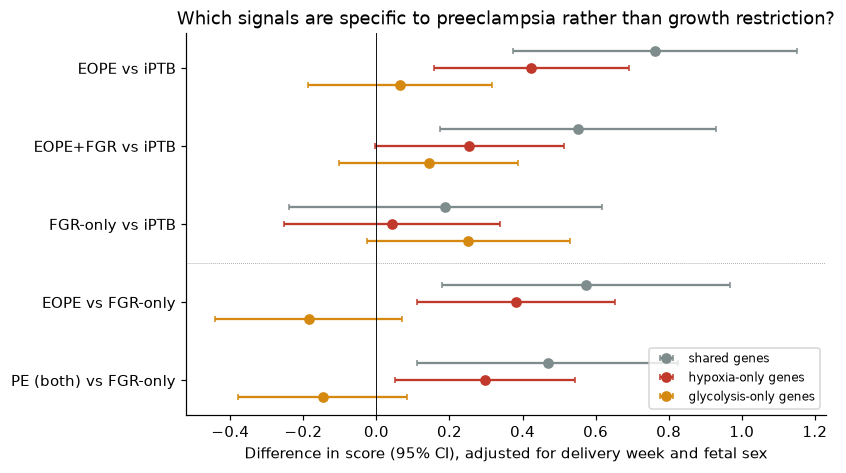

In [6]:
show = a2[(a2.se == "nonrobust") & a2.score.isin(["shared genes", "hypoxia-only genes", "glycolysis-only genes"])]
order = ["EOPE vs iPTB", "EOPE+FGR vs iPTB", "FGR-only vs iPTB", "EOPE vs FGR-only", "PE (both) vs FGR-only"]
cols = {"shared genes": "#7f8c8d", "hypoxia-only genes": "#c0392b", "glycolysis-only genes": "#d68910"}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, (sname, col) in enumerate(cols.items()):
    sub = show[show.score == sname].set_index("contrast").loc[order]
    y = np.arange(len(order)) + (i - 1) * 0.22
    ax.errorbar(sub.estimate, y, xerr=[sub.estimate - sub.CI_low, sub.CI_high - sub.estimate], fmt="o", c=col, label=sname, capsize=2)
ax.axvline(0, c="k", lw=0.6); ax.axhline(2.5, c="grey", lw=0.5, ls=":")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("Difference in score (95% CI), adjusted for delivery week and fetal sex")
ax.set_title("Which signals are specific to preeclampsia rather than growth restriction?")
ax.legend(fontsize=8, loc="lower right")
plt.savefig(FIG_DIR / "fig6_group_contrasts.png", dpi=300, bbox_inches="tight"); plt.show()